In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [60]:
iris = load_iris()
X = iris.data
y = iris.target

In [61]:
print(f"No of samples: {X.shape[0]}")
print(f"No of features: {X.shape[1]}")
print("\nClasses distribution:")
for i in np.unique(y):
  print(f"{iris.target_names[i]}: {np.sum(y==i)}")

No of samples: 150
No of features: 4

Classes distribution:
setosa: 50
versicolor: 50
virginica: 50


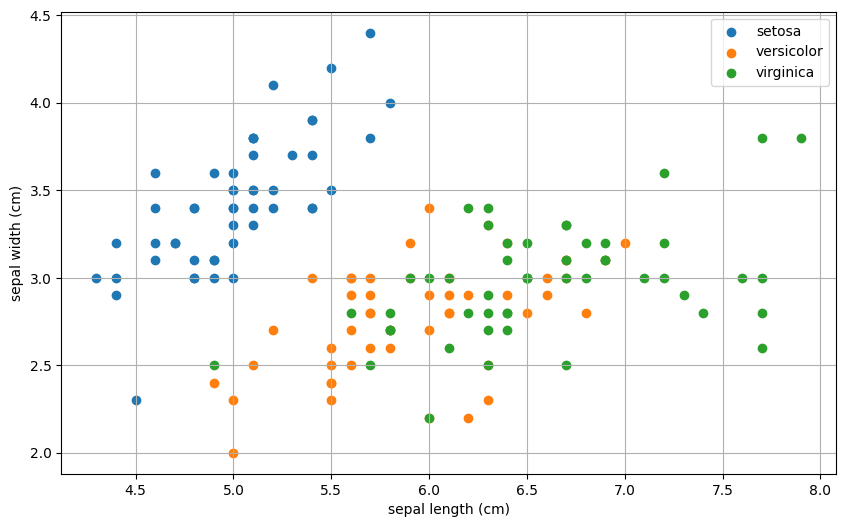

In [89]:
plt.figure(figsize=(10, 6))
plt.scatter(X[y==0, 0], X[y==0, 1], label=f"{iris.target_names[0]}")
plt.scatter(X[y==1, 0], X[y==1, 1], label=f"{iris.target_names[1]}")
plt.scatter(X[y==2, 0], X[y==2, 1], label=f"{iris.target_names[2]}")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend()
plt.grid()
plt.show()

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y
)

In [77]:
# take only virginica and versicolor
binary_index = y!=0
X_binary = X[binary_index]
y_binary = y[binary_index]

X_binary_train, X_binary_test, y_binary_train, y_binary_test = train_test_split(
    X_binary, y_binary, test_size=0.2, stratify=y_binary, random_state=80
)


In [78]:
kernels = ['linear', 'poly', 'rbf']
results_binary = []
for kernel in kernels:
  model = SVC(kernel=kernel)
  model.fit(X_binary_train, y_binary_train)
  y_binary_pred = model.predict(X_binary_test)
  print("===========================================================")
  print(f"Kernel: {kernel}")
  print("===========================================================")
  classification = classification_report(y_binary_test, y_binary_pred)
  print(f"Classification report:\n{classification}")

  cm = confusion_matrix(y_binary_test, y_binary_pred)
  print(f"Confusion matrix:\n{cm}")

  accuracy = accuracy_score(y_binary_test, y_binary_pred)
  precision = precision_score(y_binary_test, y_binary_pred)
  recall = recall_score(y_binary_test, y_binary_pred)
  f1 = f1_score(y_binary_test, y_binary_pred)

  results_binary.append([
      kernel, accuracy, precision, recall, f1
  ])

Kernel: linear
Classification report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

Confusion matrix:
[[10  0]
 [ 0 10]]
Kernel: poly
Classification report:
              precision    recall  f1-score   support

           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20

Confusion matrix:
[[ 9  1]
 [ 0 10]]
Kernel: rbf
Classification report:
              precision    recall  f1-score   support

           1       0.91      1.00      0.95        10
           2       1.00      0.90      0.95        10


In [79]:
results_binary_df = pd.DataFrame(
    results_binary,
    columns=[
        'kernel', 'accuracy', 'precision', 'recall', 'f1'
    ]
)

results_binary_df

,kernel,accuracy,precision,recall,f1
0,linear,1.00,1.000000,1.0,1.000000
1,poly,0.95,1.000000,0.9,0.947368
2,rbf,0.95,0.909091,1.0,0.952381


In [82]:
multiclass_results = []

for kernel in kernels:
  model = SVC(
      kernel = kernel
  )
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  multiclass_results.append([
      kernel,
      accuracy_score(y_test, y_pred),
      precision_score(y_test, y_pred, average='weighted'),
      recall_score(y_test, y_pred, average='weighted'),
      f1_score(y_test, y_pred, average='weighted')
  ])
  print("===========================================================")
  print(f"Kernel: {kernel}")
  print("===========================================================")

  classification = classification_report(y_test, y_pred)
  print(f"Classification report:\n{classification}")

  cm = confusion_matrix(y_test, y_pred)
  print(f"Confusion matrix:\n{cm}")

Kernel: linear
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      0.93      0.97        15
           2       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45

Confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
Kernel: poly
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      0.80      0.89        15
           2       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45

Confusion matrix:
[[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]
Kernel: rbf
Classification report:
              preci

In [85]:
results_df = pd.DataFrame(
    multiclass_results,
    columns=[
        'kernel', 'accuracy', 'precision', 'recall', 'f1'
    ]
)

results_df


,kernel,accuracy,precision,recall,f1
0,linear,0.977778,0.979167,0.977778,0.977753
1,poly,0.933333,0.944444,0.933333,0.932660
2,rbf,0.955556,0.960784,0.955556,0.955357
